# Childcare accessibility in Vienna: routing

**What this notebook does.** Computes door-to-door travel times by walking and public transport from every 250 m cell in Vienna to every childcare site, for **every minute from 07:30 to 08:29** on Tuesday 20 Oct 2026. It is the first step of the project. Every later notebook only reads what it saves:

| Output (in `outputs/`) | Used by |
|---|---|
| `routing_origins.csv`: the 6,950 cells (`origin_id` o0…, cell code, routing point) | `socioeconomic_eda.ipynb` (row order of everything) |
| `routing_destinations.csv`: the 1,682 sites (`destination_id` d0…, coordinates) | reference; same order as `Data/KINDERGARTENOGD.json` |
| `origin_destination_matrices_1min/2026-10-20_HHMM.npz`: one 6,950 × 1,682 matrix per departure minute (minutes; NaN = no trip within 30 min) | `accessibility_analysis.ipynb` |
| `nearest_site_time_by_cell.csv`: time to the nearest site per cell, summarised over the 60 departures | `access_maps.ipynb` |

**You probably don't need to run the routing.** The finished matrices are on the repository's release: `python get_data.py` downloads them, and this notebook then only checks them and rebuilds the small summary files. Routing from scratch took 3.3 hours (about 3 minutes per departure); it is resumable, so you can stop and restart it.

**Routing set-up** (fixed for the whole project)
| | |
|---|---|
| Router | [r5py](https://r5py.readthedocs.io) 1.1.7 (R5, Conveyal), needs **Java 21** |
| Network | OpenStreetMap, a box around all GTFS stops plus 2–3 km (`Data/vienna-261020.osm.pbf`, cut from the Geofabrik Austria extract of 20 Oct 2026 with `Data/socioeconomic/scripts/clip_osm_vienna.py`) |
| Timetable | Wiener Linien + Wiener Lokalbahnen GTFS (`Data/gtfs.zip`). No ÖBB S-Bahn: a limitation |
| Modes | walk only, or walk → public transport → walk; walking 4.5 km/h |
| Cut-off | 30 minutes door to door |
| Departures | every minute 07:30–08:29 (60), each a single departure (`departure_time_window` = 1 min) |
| Origins | the routing point of each Statistik Austria 250 m cell touching Vienna (`representative_point`, always inside the cell) |
| Destinations | the 1,682 childcare sites of `KINDERGARTENOGD` |

## 1. Settings and Java

In [1]:
from pathlib import Path
import os, sys, time, warnings
from datetime import datetime, timedelta
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt

_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in _candidates if (p / "Data" / "KINDERGARTENOGD.json").exists())
DATA, OUT = ROOT / "Data", ROOT / "outputs"
MATRICES = OUT / "origin_destination_matrices_1min"; MATRICES.mkdir(parents=True, exist_ok=True)

OSM_FILE = DATA / "vienna-261020.osm.pbf"
GTFS_FILE = DATA / "gtfs.zip"
GRID_ZIP = DATA / "OGDEXT_RASTER_1_STATISTIK_AUSTRIA_L000250_LAEA.zip"
GRID_MEMBER = "STATISTIK_AUSTRIA_RASTER_L000250_3035.shp"

TRAVEL_DATE = "2026-10-20"          # a Tuesday inside the GTFS service period
FIRST, LAST = "07:30", "08:29"      # every minute in this range, inclusive = 60 departures
WINDOW_MINUTES = 1                  # one real departure per matrix
MAX_MINUTES = 30                    # door-to-door cut-off
WALK_KMH = 4.5
ORIGIN_BATCH = 1000                 # origins per R5 call (memory vs. overhead)

# R5 needs Java 21: use JAVA_HOME if set, else Homebrew's openjdk@21 (macOS)
for java_home in [os.environ.get("JAVA_HOME", ""),
                  "/opt/homebrew/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home",
                  "/usr/local/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home"]:
    if java_home and Path(java_home, "bin", "java").exists():
        os.environ["JAVA_HOME"] = java_home
        os.environ["PATH"] = str(Path(java_home, "bin")) + os.pathsep + os.environ["PATH"]
        break

# Java heap: about 75% of RAM. Must be set before r5py is imported (restart the kernel to change it).
try:
    import psutil
    HEAP_GB = max(4, int(psutil.virtual_memory().total / 1024**3 * 0.75))
    if "r5py" not in sys.modules and "--max-memory" not in sys.argv:
        sys.argv += ["--max-memory", f"{HEAP_GB}G"]
except ImportError:
    HEAP_GB = None                  # r5py's own default
print(f"Java: {os.environ.get('JAVA_HOME', 'not set')} | heap: {HEAP_GB or 'r5py default'} GB")

Java: /opt/homebrew/opt/openjdk@21/libexec/openjdk.jdk/Contents/Home | heap: 6 GB


## 2. Origins and destinations
Built from the raw files, then saved, so every later notebook uses the same ids and order. If the raw grid is not downloaded (`python get_data.py --routing`), the saved files are used.

In [2]:
ORIG_FILE, DEST_FILE = OUT / "routing_origins.csv", OUT / "routing_destinations.csv"
fac = gpd.read_file(DATA / "KINDERGARTENOGD.json").to_crs(4326)
destinations = gpd.GeoDataFrame({"id": [f"d{i}" for i in range(len(fac))]}, geometry=fac.geometry, crs=4326)

if GRID_ZIP.exists():
    districts = gpd.read_file(DATA / "BEZIRKSGRENZEOGD.json")
    grid = gpd.read_file(f"/vsizip/{GRID_ZIP.resolve()}/{GRID_MEMBER}",
                         mask=districts.to_crs("EPSG:3035")).reset_index(drop=True)      # cells touching Vienna
    pts = grid.to_crs("EPSG:32633").geometry.representative_point().to_crs(4326)
    orig_df = pd.DataFrame({"origin_id": [f"o{i}" for i in range(len(grid))], "gid": grid["gid"],
                            "cellcode": grid["cellcode"], "lon": pts.x.round(10), "lat": pts.y.round(10)})
    orig_df.to_csv(ORIG_FILE, index=False)
    pd.DataFrame({"destination_id": destinations["id"], "lon": fac.geometry.x, "lat": fac.geometry.y}).to_csv(DEST_FILE, index=False)
    print(f"built {len(orig_df):,} origins and {len(destinations):,} destinations from the raw files")
else:
    orig_df = pd.read_csv(ORIG_FILE)
    print(f"raw grid not downloaded: using saved {ORIG_FILE.name} ({len(orig_df):,} origins)")

origins = gpd.GeoDataFrame({"id": orig_df["origin_id"]}, geometry=gpd.points_from_xy(orig_df.lon, orig_df.lat), crs=4326)
origin_ids = origins["id"].astype(str).to_numpy(dtype=object)
destination_ids = destinations["id"].astype(str).to_numpy(dtype=object)

first = datetime.strptime(f"{TRAVEL_DATE} {FIRST}", "%Y-%m-%d %H:%M")
last = datetime.strptime(f"{TRAVEL_DATE} {LAST}", "%Y-%m-%d %H:%M")
DEPARTURES = [first + timedelta(minutes=k) for k in range(int((last - first).total_seconds() // 60) + 1)]
out_file = lambda dep: MATRICES / f"{TRAVEL_DATE}_{dep:%H%M}.npz"

def is_complete(path):
    try:
        with np.load(path, allow_pickle=True) as z:
            return (z["travel_times"].shape == (len(origin_ids), len(destination_ids))
                    and np.array_equal(z["origin_ids"].astype(str), origin_ids.astype(str))
                    and int(z["window_minutes"]) == WINDOW_MINUTES)
    except Exception:
        return False

todo = [d for d in DEPARTURES if not is_complete(out_file(d))]
print(f"{len(DEPARTURES)} departures {FIRST}–{LAST}: {len(DEPARTURES) - len(todo)} already done, {len(todo)} to route")

built 6,950 origins and 1,682 destinations from the raw files


60 departures 07:30–08:29: 60 already done, 0 to route


## 3. Route every minute (resumable)
For each missing departure minute: route all origins in batches, assemble the 6,950 × 1,682 matrix and save it. Each file is written under a temporary name and renamed when complete, so an interrupted run never leaves a half-written matrix; finished minutes are skipped on the next run. Building the network from the OSM and GTFS files takes a few minutes. The first departure is timed and the cell prints how long the rest will take.

r5py warns that time windows under 5 minutes "may cause adverse effects". On this fully scheduled timetable they do not: in Nov 2026 we checked that the 5th-fastest of ten one-minute runs reproduces R5's own 10-minute-window result on 100% of cell–site pairs.

In [3]:
if todo:
    import r5py
    missing = [p.name for p in [OSM_FILE, GTFS_FILE] if not p.exists()]
    if missing:
        raise FileNotFoundError(f"Routing needs {missing} in Data/: run `python get_data.py --routing`, "
                                "or `python get_data.py` to download the finished matrices instead.")
    warnings.filterwarnings("ignore", message=".*departure time window is below 5 minutes.*")
    signature = "|".join(map(str, [TRAVEL_DATE, MAX_MINUTES, WALK_KMH, "TRANSIT+WALK_DIRECT+WALK_ACCESS_EGRESS",
                                   f"window={WINDOW_MINUTES}min", "osm=vienna-261020 (clipped)",
                                   GTFS_FILE.stat().st_size, "r5py=" + r5py.__version__]))
    opos = {v: i for i, v in enumerate(origin_ids)}; dpos = {v: i for i, v in enumerate(destination_ids)}
    t0 = time.time()
    network = r5py.TransportNetwork(OSM_FILE, [GTFS_FILE])
    print(f"network built in {(time.time() - t0) / 60:.1f} min")

    def route(dep, origin_rows=None):
        rows = origins if origin_rows is None else origins.iloc[origin_rows]
        M = np.full((len(origin_ids), len(destination_ids)), np.nan, dtype=np.float32)
        for s in range(0, len(rows), ORIGIN_BATCH):
            m = r5py.TravelTimeMatrix(
                network, rows.iloc[s:s + ORIGIN_BATCH], destinations,
                departure=dep, departure_time_window=timedelta(minutes=WINDOW_MINUTES),
                transport_modes=[r5py.TransportMode.TRANSIT, r5py.TransportMode.WALK],
                access_modes=[r5py.TransportMode.WALK], egress_modes=[r5py.TransportMode.WALK],
                speed_walking=WALK_KMH, max_time=timedelta(minutes=MAX_MINUTES),
                max_time_walking=timedelta(minutes=MAX_MINUTES))
            tt = m["travel_time"]
            tt = tt.dt.total_seconds() / 60 if pd.api.types.is_timedelta64_dtype(tt) else pd.to_numeric(tt, errors="coerce")
            M[m["from_id"].map(opos).to_numpy(), m["to_id"].map(dpos).to_numpy()] = tt.to_numpy(np.float32)
        return M

    times = []
    for i, dep in enumerate(todo):
        t = time.time()
        M = route(dep)
        tmp = out_file(dep).with_suffix(".partial.npz")
        np.savez_compressed(tmp, travel_times=M, origin_ids=origin_ids, destination_ids=destination_ids,
                            signature=signature, departure=f"{dep:%Y-%m-%d %H:%M}", window_minutes=WINDOW_MINUTES)
        os.replace(tmp, out_file(dep))
        times.append(time.time() - t)
        left = (len(todo) - i - 1) * np.mean(times)
        print(f"{dep:%H:%M} done in {times[-1] / 60:.1f} min | {i + 1}/{len(todo)} | about {left / 3600:.1f} h left", flush=True)
else:
    print("all departures present: nothing to route")

all departures present: nothing to route


## 4. Checks and per-cell summary
Every departure must be present with the right shape and id order. Then each matrix is reduced to the **time to the nearest site** per cell, summarised over the 60 departures (median, 90th percentile, SD, share of departures within 15 min) and saved for `access_maps.ipynb`. The plot shows how reach changes over the hour.

saved nearest_site_time_by_cell.csv | cells never reaching a site within 30 min: 1,202 (mostly forest, farmland and water)


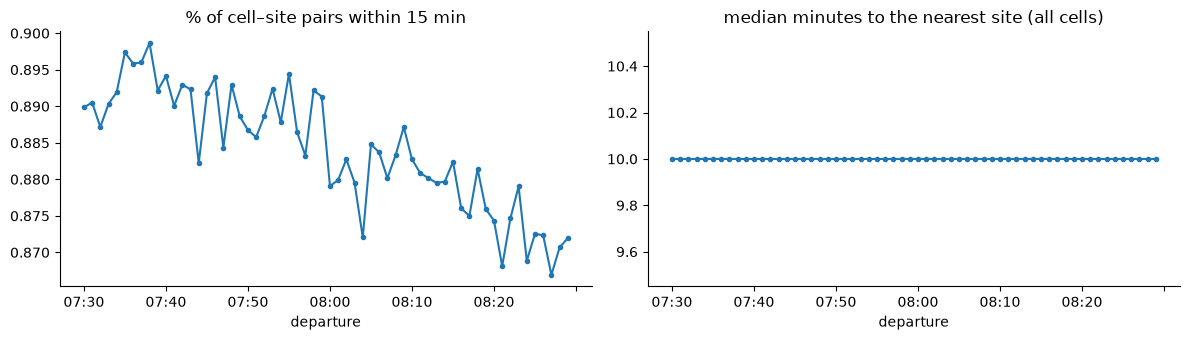

In [4]:
assert all(is_complete(out_file(d)) for d in DEPARTURES), "some departures are missing or incomplete: rerun §3"
near, rows = [], []
for d in DEPARTURES:
    with np.load(out_file(d), allow_pickle=True) as z:
        M = z["travel_times"]
    n = np.min(np.where(np.isfinite(M), M, np.inf), axis=1); n[np.isinf(n)] = np.nan
    near.append(n)
    rows.append({"departure": f"{d:%H:%M}", "pairs_within_15_pct": np.mean(M <= 15) * 100,
                 "median_nearest_min": np.median(np.nan_to_num(n, nan=MAX_MINUTES))})
N = np.array(near)                                                     # (departure, cell)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)                    # cells never reached give all-NaN columns
    summary = pd.DataFrame({"origin_id": origin_ids,
                            "nearest_median_min": np.nanmedian(N, axis=0),
                            "nearest_p90_min": np.nanpercentile(N, 90, axis=0),
                            "nearest_min_min": np.nanmin(N, axis=0),
                            "nearest_max_min": np.nanmax(N, axis=0),
                            "nearest_sd_min": np.nanstd(N, axis=0),
                            "share_departures_within_15": (np.nan_to_num(N, nan=99) <= 15).mean(axis=0),
                            "share_departures_reachable": np.isfinite(N).mean(axis=0)})
summary.round(3).to_csv(OUT / "nearest_site_time_by_cell.csv", index=False)
print(f"saved nearest_site_time_by_cell.csv | cells never reaching a site within {MAX_MINUTES} min: "
      f"{(summary.share_departures_reachable == 0).sum():,} (mostly forest, farmland and water)")

by_dep = pd.DataFrame(rows).set_index("departure")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
by_dep["pairs_within_15_pct"].plot(ax=ax[0], marker=".", title="% of cell–site pairs within 15 min")
by_dep["median_nearest_min"].plot(ax=ax[1], marker=".", title="median minutes to the nearest site (all cells)")
for a in ax:
    a.set_xlabel("departure"); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()